<a href="https://colab.research.google.com/github/LiweiWang-Serena/Merchy-AI/blob/main/merchy_ai_chatbot_feedback_dataclean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Merchy-AI Chatbot: Feedback Data Cleaning

eBay feedback issue classifier and two-store comparison.

1. Load the cleaned feedback of both stores (no buyer details).
2. Label every comment with Claude (LLM-assisted annotation).
3. Cross-check the labels against eBay's own on-time-delivery answers.
4. Hand-check a sample of labels: this is the test set.
5. Train a TF-IDF + logistic regression classifier and evaluate it on the hand-checked set.
6. Compare the two stores' problems.

**Before starting:** in Google Drive, folder `merchy-ai` holds `feedback_clean_pauleagle.csv` and `feedback_clean_fellers.csv`. Add `ANTHROPIC_API_KEY` under the key icon (Secrets) in the left sidebar and allow notebook access.

## 1. Load both stores

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
from pathlib import Path

FOLDER = Path('/content/drive/MyDrive/merchy-ai')
STORES = {'Paul Eagle': 'feedback_clean_pauleagle.csv',
          'fellers': 'feedback_clean_fellers.csv'}

frames = []
for store, name in STORES.items():
    d = pd.read_csv(FOLDER / name, dtype={'feedback_id': str})
    d['store'] = store
    d['uid'] = store + '-' + d['feedback_id']   # unique across stores
    frames.append(d)
df = pd.concat(frames, ignore_index=True)
print(len(df), 'comments')
pd.crosstab(df['store'], df['comment_type'], margins=True)

Mounted at /content/drive
2784 comments


comment_type,NEGATIVE,NEUTRAL,POSITIVE,All
store,,,,
Paul Eagle,100,63,1173,1336
fellers,81,66,1301,1448
All,181,129,2474,2784


## 2. Categories

Edit after reading the negative and neutral comments. Short, distinct descriptions: the same text guides Claude and you.

In [2]:
CATEGORIES = {
    'positive':        'Happy with the order; no problem mentioned.',
    'shipping':        'Slow, late or lost delivery; tracking problems.',
    'fitment':         'Part did not fit the stated vehicle or equipment.',
    'quality':         'Part broke, failed, was defective or poorly made.',
    'not_as_described':'Item differed from the listing (wrong item, size, color, missing pieces).',
    'packaging':       'Arrived damaged because of packing.',
    'service':         'Communication, returns, refunds or how the seller handled a problem.',
    'other':           'Anything else.',
}
ISSUES = [c for c in CATEGORIES if c != 'positive']

## 3. Label with Claude

25 comments per request; progress is saved to Drive after every batch, so re-running continues where it stopped. About 2,800 comments with Haiku costs around a dollar or two.

In [10]:
for m in client.models.list():
    if 'generateContent' in (m.supported_actions or []) and 'flash' in m.name:
        print(m.name)

models/gemini-2.5-flash
models/gemini-2.5-flash-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts


In [20]:
!pip -q install google-genai
import json, time
from google import genai
from google.colab import userdata

client = genai.Client(api_key=userdata.get('GOOGLE_API_KEY'))
MODEL = 'gemini-3.5-flash-lite'
LABELS_FILE = FOLDER / 'feedback_labels_llm_both.csv'

cat_text = '\n'.join(f'- {k}: {v}' for k, v in CATEGORIES.items())
SYSTEM = f'''You label eBay buyer feedback for motorcycle and small-engine parts sellers.
Categories:
{cat_text}
Pick the single category that best describes the main point of each comment.
Reply with only a JSON object mapping each id to a category name. No other text.'''

done = (pd.read_csv(LABELS_FILE, dtype=str) if LABELS_FILE.exists()
        else pd.DataFrame(columns=['uid', 'llm_label']))
todo = df[~df['uid'].isin(done['uid'])]
print(len(todo), 'left to label')

for start in range(0, len(todo), 100):
    batch = todo.iloc[start:start + 100]
    items = {r.uid: r.comment_text for r in batch.itertuples()}
    try:
        resp = client.models.generate_content(
            model=MODEL,
            contents=json.dumps(items, ensure_ascii=False),
            config={'system_instruction': SYSTEM})
        text = resp.text.strip().removeprefix('```json').removesuffix('```').strip()
        labels = json.loads(text)
    except Exception as e:
        print('Batch skipped (will retry on the next run):', str(e)[:150])
        time.sleep(10)
        continue
    rows = [{'uid': k, 'llm_label': v if v in CATEGORIES else 'other'} for k, v in labels.items() if k in items]
    done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True)
    done.to_csv(LABELS_FILE, index=False)
    print(f'{len(done)} labeled')
    time.sleep(4)

1 left to label
2784 labeled


In [21]:
print(len(pd.read_csv(LABELS_FILE)), 'already labeled')
try:
    client.models.generate_content(model=MODEL, contents='hi')
except Exception as e:
    print(str(e)[:600])

2784 already labeled


In [22]:
labels = pd.read_csv(LABELS_FILE, dtype=str).drop_duplicates('uid')
data = df.merge(labels, on='uid')
print(len(data), 'of', len(df), 'labeled')
pd.crosstab(data['llm_label'], data['store'])

2784 of 2784 labeled


store,Paul Eagle,fellers
llm_label,,
fitment,54,73
not_as_described,53,40
other,16,16
packaging,14,17
positive,899,882
quality,50,90
service,44,58
shipping,206,272


## 4. Cross-check against eBay's on-time answers

Some buyers told eBay directly that the item was not delivered within the estimated range. Independent of Claude, so most of these should be labeled `shipping`.

In [23]:
late = data['ratings'].str.contains('NOT_DELIVERED_WITHIN', na=False)
print(late.sum(), 'comments where the buyer told eBay it arrived late. Claude labeled them:')
print(data[late]['llm_label'].value_counts())
data[late][['store', 'comment_text', 'llm_label']]

54 comments where the buyer told eBay it arrived late. Claude labeled them:
llm_label
shipping     39
service      14
packaging     1
Name: count, dtype: int64


,store,comment_text,llm_label
32,Paul Eagle,Never received item,shipping
34,Paul Eagle,Not sure what happened but I could drove and p...,shipping
41,Paul Eagle,I have not received this purchase 9 days after...,shipping
47,Paul Eagle,I still not have received my product. Got an e...,shipping
48,Paul Eagle,Order my item on 3-13-26 now 13 days later sti...,shipping
49,Paul Eagle,"The item never arrived. I got a refund, but th...",shipping
52,Paul Eagle,Pase 20 dias esperando mi paquete nunca lo env...,shipping
55,Paul Eagle,Not responding using same letter to all old an...,service
58,Paul Eagle,Haven't got it,shipping
60,Paul Eagle,Well I might never know the quality of what I ...,shipping


## 5. Hand-check a test set

150 comments, balanced across the two stores and over-sampling negative and neutral ones so the rare categories appear. Open the file in Google Sheets, put the correct category in `checked_label` (copy `llm_label` when it's right), download it as CSV and replace the file in Drive with the same name. Then run the next cell.

In [27]:
CHECK_FILE = FOLDER / 'feedback_check_both.csv'
if not CHECK_FILE.exists():
    parts = []
    for store in STORES:
        s = data[data['store'] == store]
        issues = s[s['comment_type'] != 'POSITIVE']
        pos = s[s['comment_type'] == 'POSITIVE']
        parts += [issues.sample(min(45, len(issues)), random_state=0),
                  pos.sample(min(30, len(pos)), random_state=0)]
    sample = pd.concat(parts).sample(frac=1, random_state=0)   # shuffle so stores are mixed
    sample[['uid', 'store', 'comment_type', 'comment_text', 'llm_label']].assign(checked_label='') \
        .to_csv(CHECK_FILE, index=False)
    print('Wrote', CHECK_FILE, '- fill in checked_label, then run the next cell.')
else:
    print(CHECK_FILE, 'already exists; not overwriting your checks.')

Wrote /content/drive/MyDrive/merchy-ai/feedback_check_both.csv - fill in checked_label, then run the next cell.


In [37]:
check = pd.read_csv(CHECK_FILE, dtype=str)
check['checked_label'] = check['checked_label'].fillna('').str.strip()
check = check[check['checked_label'] != '']
bad = set(check['checked_label']) - set(CATEGORIES)
if bad:
    print('Unknown categories in checked_label (fix spelling):', bad)
print(len(check), 'hand-checked comments')
print('Claude label accuracy vs. your checks:', round((check['llm_label'] == check['checked_label']).mean(), 3))

150 hand-checked comments
Claude label accuracy vs. your checks: 0.853


## 6. Train and evaluate

Trains on Claude's labels for every comment not in the hand-checked set, from both stores, and evaluates on your hand-checked labels. `class_weight='balanced'` stops it from predicting `positive` for everything.

In [34]:
drive.mount('/content/drive', force_remount=True)
print([f for f in os.listdir(FOLDER) if 'check' in f])
c = pd.read_csv(CHECK_FILE, dtype=str)
print(c['checked_label'].notna().sum(), 'filled in')

Mounted at /content/drive
['feedback_check_both.gsheet', 'feedback_check_both (1).csv']


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/merchy-ai/feedback_check_both.csv'

In [35]:
import glob
found = glob.glob(str(FOLDER / 'feedback_check_both*.csv'))
print(found)
CHECK_FILE = Path(found[0])
c = pd.read_csv(CHECK_FILE, dtype=str)
print(c['checked_label'].notna().sum(), 'filled in')

['/content/drive/MyDrive/merchy-ai/feedback_check_both (1).csv']
150 filled in


                  precision    recall  f1-score   support

         fitment       0.62      0.44      0.52        18
not_as_described       0.33      0.29      0.31        14
           other       0.00      0.00      0.00         0
       packaging       0.00      0.00      0.00         2
        positive       0.87      0.52      0.65        52
         quality       0.23      0.45      0.30        11
         service       0.48      0.69      0.56        16
        shipping       0.74      0.62      0.68        37

        accuracy                           0.52       150
       macro avg       0.41      0.38      0.38       150
    weighted avg       0.66      0.52      0.57       150



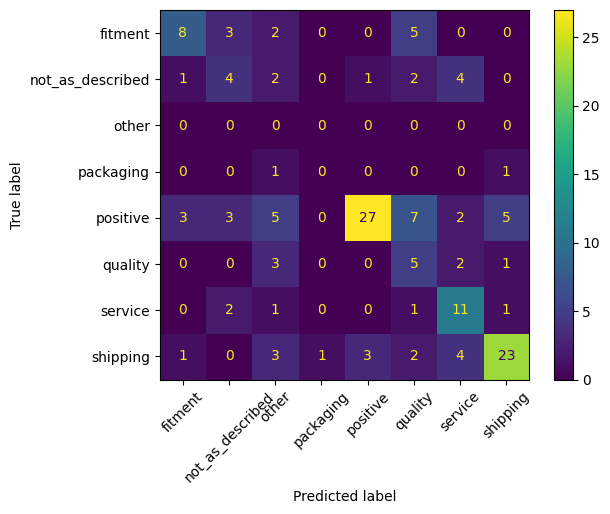

In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

train = data[~data['uid'].isin(check['uid'])]
model = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=2000, class_weight='balanced'),
)
model.fit(train['comment_text'], train['llm_label'])

pred = model.predict(check['comment_text'])
print(classification_report(check['checked_label'], pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(check['checked_label'], pred, xticks_rotation=45);

The mistakes show which categories overlap or need clearer descriptions.

In [39]:
errors = check.assign(pred=pred)
errors[errors['pred'] != errors['checked_label']][['store', 'comment_text', 'checked_label', 'pred']]

,store,comment_text,checked_label,pred
2,Paul Eagle,I needed a carb for a 27hp briggs twin cylinde...,fitment,other
3,fellers,I didn't get my part on time I emailed them th...,shipping,service
6,Paul Eagle,Well I might never know the quality of what I ...,service,not_as_described
7,fellers,"In reality, the cable is not 74 inches as the ...",fitment,not_as_described
9,Paul Eagle,As described should work great,positive,not_as_described
...,...,...,...,...
138,Paul Eagle,Defective part waiting on refund,quality,service
139,Paul Eagle,As described thanks,positive,not_as_described
141,Paul Eagle,Fast shipping,positive,shipping
142,fellers,Good part but wasn't for the mower its describ...,fitment,not_as_described


## 7. Compare the two stores

Shares are out of each store's **written** buyer comments, so they compare what buyers complain about, not how often they complain. (The two stores' feedback may also cover different time spans.)

Problems by category, % of each store's problem comments:


store,Paul Eagle,fellers,Paul Eagle (n),fellers (n)
llm_label,,,,
fitment,12.4,12.9,54,73
not_as_described,12.1,7.1,53,40
other,3.7,2.8,16,16
packaging,3.2,3.0,14,17
quality,11.4,15.9,50,90
service,10.1,10.2,44,58
shipping,47.1,48.1,206,272


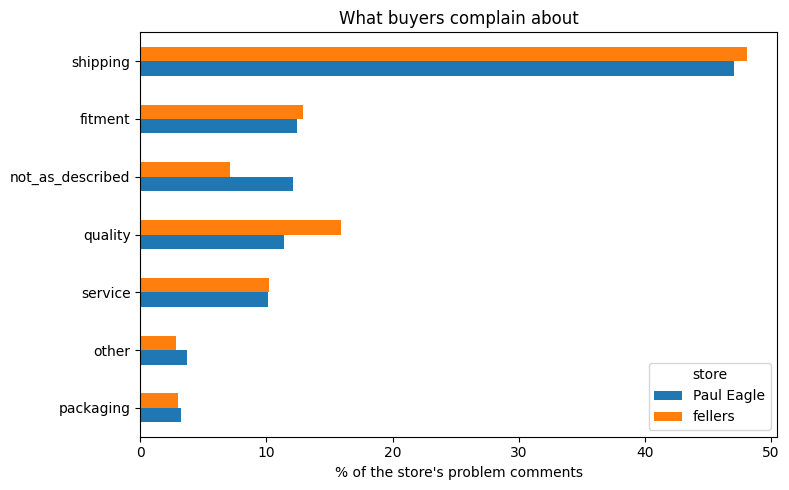

In [40]:
import matplotlib.pyplot as plt

issues_only = data[data['llm_label'].isin(ISSUES)]
counts = pd.crosstab(issues_only['llm_label'], issues_only['store'])
share = (counts / counts.sum() * 100).round(1)

print('Problems by category, % of each store\'s problem comments:')
display(share.assign(**{c + ' (n)': counts[c] for c in counts.columns}))

ax = share.sort_values(share.columns[0]).plot.barh(figsize=(8, 5))
ax.set_xlabel('% of the store\'s problem comments')
ax.set_ylabel('')
ax.set_title('What buyers complain about')
plt.tight_layout()
plt.savefig(FOLDER / 'store_comparison.png', dpi=150)
plt.show()

In [ ]:
# Read the comments behind any bar, e.g. fitment problems at Paul Eagle
issues_only[(issues_only['store'] == 'Paul Eagle') & (issues_only['llm_label'] == 'fitment')][['comment_type', 'comment_text']]

## 8. Save

In [41]:
import joblib
joblib.dump(model, FOLDER / 'feedback_classifier.joblib')
data.drop(columns=['feedback_id']).to_csv(FOLDER / 'feedback_labeled_both.csv', index=False)
print('Saved model, labeled data and chart to Drive.')
print(model.predict(['Part did not fit my 2015 Honda', 'Fast shipping, thanks!']))

Saved model, labeled data and chart to Drive.
['fitment' 'shipping']


## Feedback data pipeline and issue classifier

- Pulled 17,900 feedback entries for two stores through the eBay Feedback API, and cleaned them down to 2,784 comments written by buyers (automated eBay feedback, empty comments, duplicates and buyer details removed).
- Labeled every comment by issue type with Gemini, then hand-checked a stratified sample of 150; the LLM labels agreed with the hand-checked labels 85% of the time.
- Trained a TF-IDF + logistic regression baseline classifier on the LLM labels. It reached 52% accuracy on the hand-checked set. Error analysis points to two causes: too few training examples for the rarer issue types, and a bag-of-words model that can't tell praise ("fast shipping") from complaints ("slow shipping").
- Compared the distribution of issue types between the two stores.

## NEXT STEP


## Plan for Next Week

**1. Relabel with prompt v2 and compare against v1**
- Relabel all 2,784 comments with prompt v2, which defines shipping as a delivery problem and counts praise for fast shipping as positive (about 28 API calls).
- Compare v1 and v2 accuracy on the 150 hand-checked comments, and export train, validation and test sets for fine-tuning.

**2. Fine-tune a DistilBERT complaint classifier**
- Train on a Colab T4 GPU, reading the train, validation and test files from `finetune_data_v2/`.
- Handle class imbalance (positive comments dominate) by giving minority classes higher weight during training.
- Fine-tune DistilBERT with Hugging Face `transformers` for 3 to 5 epochs, scoring each epoch on the validation set and keeping the best checkpoint.
- Evaluate on the test set: accuracy, macro F1, per-class precision and recall, and a confusion matrix.
- Compare against the baselines: TF-IDF (52%), Gemini prompt v1 (85.3%) and Gemini prompt v2.
- Measure per-comment inference latency and cost, compared with calling the Gemini API.
- Log results to MLflow and save the versioned model to Drive.